SPLIT: spectral_centroid_mean_mean <= 2335.9602
  node   n  CA  AZ  TX  entropy_bits   gini
Parent 150  52  58  40       1.56840 0.6592
  Left  50  31   6  13       1.29994 0.5336
 Right 100  21  52  27       1.47342 0.6126

Weighted child entropy: 1.415596 bits
Information gain:       0.152804 bits
Gini reduction:         0.072933
Manual entropy calculation matches sklearn.


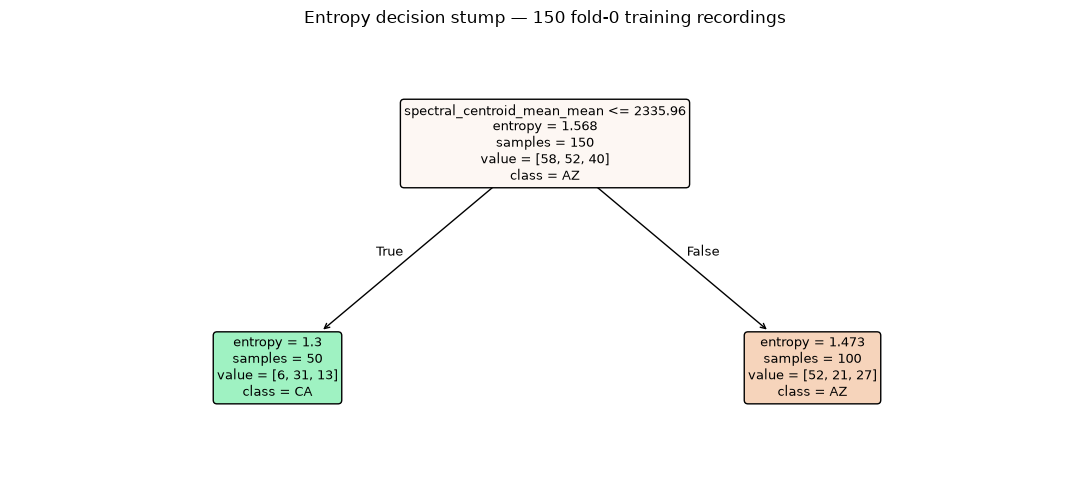

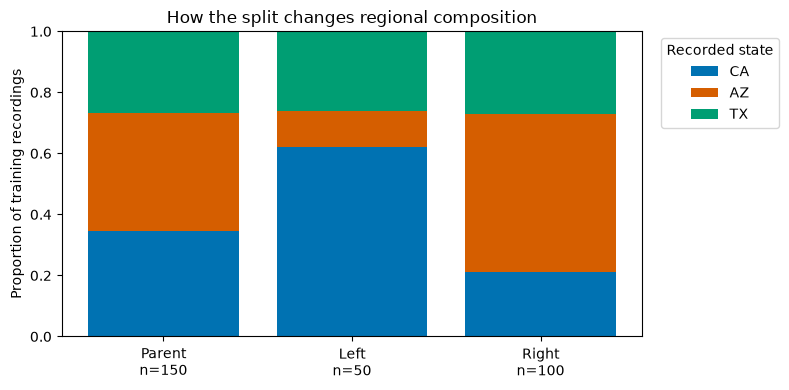


Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\decision_trees\worked_split_20261030T031446273967Z


In [1]:
#  A real, verified decision-tree split

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

roots = [
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/acoustic_features_recording.csv").is_file()
]
assert len(roots) == 1
PROJECT_ROOT = roots[0]

artifact_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / "assignment_artifacts_20261030T020845905141Z"
)
artifacts = json.loads(
    (artifact_dir / "artifact_manifest.json").read_text(encoding="utf-8")
)
feature_names = artifacts["feature_allowlist"]
CLASSES = ["CA", "AZ", "TX"]

module_path = PROJECT_ROOT / "research/src/supervised/representations.py"
assert hashlib.sha256(module_path.read_bytes()).hexdigest() == (
    artifacts["representation_module_sha256"]
)

source_dir = str(PROJECT_ROOT / "research/src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)
from supervised.representations import make_representations

fold_manifest = pd.read_csv(
    PROJECT_ROOT / artifacts["development_folds"],
    dtype={"recording_id": "string"},
)
training_export = pd.read_csv(
    artifact_dir / "development_train.csv",
    dtype={"recording_id": "string"},
)

assert training_export["recording_id"].is_unique
assert set(training_export["recording_id"]) == set(fold_manifest["recording_id"])

ordered = training_export.set_index("recording_id").loc[
    fold_manifest["recording_id"]
]
assert np.array_equal(
    ordered["model_state"].to_numpy(),
    fold_manifest["model_state"].to_numpy(),
)
assert np.array_equal(
    ordered["location_group"].to_numpy(),
    fold_manifest["location_group"].to_numpy(),
)

X = ordered[feature_names].reset_index(drop=True)
y = fold_manifest["model_state"].reset_index(drop=True)
assert X.shape == (184, 50)
assert np.isfinite(X.to_numpy()).all()

train_idx = np.flatnonzero(
    fold_manifest["validation_fold"].to_numpy() != 0
)
validation_idx = np.flatnonzero(
    fold_manifest["validation_fold"].to_numpy() == 0
)
assert set(
    fold_manifest.iloc[train_idx]["location_group"]
).isdisjoint(fold_manifest.iloc[validation_idx]["location_group"])
assert len(train_idx) == 150

transformer = make_representations()["continuous"]
X_train = transformer.fit_transform(X.iloc[train_idx])
y_train = y.iloc[train_idx].to_numpy()

stump = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=1,
    min_samples_leaf=5,
    random_state=42,
)
stump.fit(X_train, y_train)

tree = stump.tree_
feature_index = tree.feature[0]
assert feature_index >= 0, "No split found; stop and inspect."
threshold = tree.threshold[0]
split_feature = feature_names[feature_index]

# Match sklearn's internal input precision.
left_mask = X_train[:, feature_index].astype(np.float32) <= threshold

def class_counts(labels):
    return np.array([(labels == state).sum() for state in CLASSES])

def entropy(counts):
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log2(p)).sum())

def gini(counts):
    p = counts / counts.sum()
    return float(1 - np.sum(p ** 2))

counts = {
    "Parent": class_counts(y_train),
    "Left": class_counts(y_train[left_mask]),
    "Right": class_counts(y_train[~left_mask]),
}
assert np.array_equal(counts["Parent"], counts["Left"] + counts["Right"])

split_calculation = pd.DataFrame([
    {
        "node": node,
        "n": int(values.sum()),
        **dict(zip(CLASSES, values)),
        "entropy_bits": entropy(values),
        "gini": gini(values),
    }
    for node, values in counts.items()
])

weights = {
    side: counts[side].sum() / len(y_train)
    for side in ["Left", "Right"]
}
weighted_entropy = sum(
    weights[side] * entropy(counts[side]) for side in weights
)
information_gain = entropy(counts["Parent"]) - weighted_entropy
gini_reduction = gini(counts["Parent"]) - sum(
    weights[side] * gini(counts[side]) for side in weights
)

left_node, right_node = tree.children_left[0], tree.children_right[0]
sklearn_gain = tree.impurity[0] - (
    tree.n_node_samples[left_node] * tree.impurity[left_node]
    + tree.n_node_samples[right_node] * tree.impurity[right_node]
) / tree.n_node_samples[0]

assert np.isclose(entropy(counts["Parent"]), tree.impurity[0])
assert np.isclose(information_gain, sklearn_gain)
assert counts["Left"].sum() == tree.n_node_samples[left_node]
assert counts["Right"].sum() == tree.n_node_samples[right_node]

print(f"SPLIT: {split_feature} <= {threshold:.8g}")
print(split_calculation.round(5).to_string(index=False))
print(f"\nWeighted child entropy: {weighted_entropy:.6f} bits")
print(f"Information gain:       {information_gain:.6f} bits")
print(f"Gini reduction:         {gini_reduction:.6f}")
print("Manual entropy calculation matches sklearn.")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
dt_example_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/decision_trees"
    / f"worked_split_{stamp}"
)
dt_example_dir.mkdir(parents=True, exist_ok=False)

# Figure 1: the actual fitted rule.
fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(
    stump,
    feature_names=feature_names,
    class_names=list(stump.classes_),
    filled=True, rounded=True, precision=3, fontsize=9, ax=ax,
)
ax.set_title("Entropy decision stump — 150 fold-0 training recordings")
fig.tight_layout()
fig.savefig(dt_example_dir / "annotated_stump.png", dpi=180)
plt.show()
plt.close(fig)

# Figure 2: class proportions, with sample sizes explicitly labeled.
fig, ax = plt.subplots(figsize=(8, 4))
node_names = list(counts)
bottom = np.zeros(3)
colors = {"CA": "#0072B2", "AZ": "#D55E00", "TX": "#009E73"}

for index, state in enumerate(CLASSES):
    proportions = np.array([
        counts[node][index] / counts[node].sum() for node in node_names
    ])
    ax.bar(node_names, proportions, bottom=bottom,
           label=state, color=colors[state])
    bottom += proportions

ax.set_xticks(
    range(3),
    [f"{node}\nn={counts[node].sum()}" for node in node_names],
)
ax.set_ylabel("Proportion of training recordings")
ax.set_ylim(0, 1)
ax.set_title("How the split changes regional composition")
ax.legend(title="Recorded state", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
fig.savefig(dt_example_dir / "split_class_composition.png", dpi=180)
plt.show()
plt.close(fig)

split_calculation.to_csv(
    dt_example_dir / "split_calculation.csv", index=False
)
(dt_example_dir / "split_details.json").write_text(
    json.dumps({
        "feature": split_feature,
        "threshold_full_precision": float(threshold),
        "information_gain_bits": information_gain,
        "gini_reduction_same_split": gini_reduction,
        "training_fold_excluded": 0,
        "training_n": len(y_train),
        "purpose": "Teaching example; threshold selected using entropy",
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved:", dt_example_dir)

In [2]:
# Tree configurations and bounded pruning search
# Same saved development folds. No final-test evaluation.

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)

tree_specs = [
    {
        "name": "Gini_depth3",
        "family": "fixed_gini",
        "criterion": "gini",
        "max_depth": 3,
        "min_samples_leaf": 5,
        "ccp_alpha": 0.0,
    },
    {
        "name": "Entropy_depth5",
        "family": "fixed_entropy",
        "criterion": "entropy",
        "max_depth": 5,
        "min_samples_leaf": 5,
        "ccp_alpha": 0.0,
    },
]

for alpha in [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]:
    tree_specs.append({
        "name": f"Gini_pruning_{alpha:g}",
        "family": "pruning_reference" if alpha == 0 else "pruning_candidate",
        "criterion": "gini",
        "max_depth": None,
        "min_samples_leaf": 5,
        "ccp_alpha": alpha,
    })

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
dt_search_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/decision_trees"
    / f"development_search_{stamp}"
)
dt_search_dir.mkdir(parents=True, exist_ok=False)

(dt_search_dir / "search_protocol.json").write_text(
    json.dumps({
        "configurations": tree_specs,
        "selection_metric": "Mean validation-fold macro-F1",
        "pruning_selection": "Positive-alpha candidates only",
        "tie_rule": (
            "Within 1e-12 of maximum: fewer mean leaves, then larger alpha"
        ),
        "fold_manifest": artifacts["development_folds"],
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

tree_fold_rows = []
tree_prediction_rows = []

for spec in tree_specs:
    parameters = {
        key: spec[key]
        for key in ["criterion", "max_depth", "min_samples_leaf", "ccp_alpha"]
    }

    for fold in range(5):
        validation_mask = fold_manifest["validation_fold"].eq(fold)
        tr = np.flatnonzero(~validation_mask.to_numpy())
        va = np.flatnonzero(validation_mask.to_numpy())

        assert set(
            fold_manifest.iloc[tr]["location_group"]
        ).isdisjoint(fold_manifest.iloc[va]["location_group"])

        pipeline = Pipeline([
            ("representation", make_representations()["continuous"]),
            ("classifier", DecisionTreeClassifier(
                **parameters, random_state=42
            )),
        ])
        pipeline.fit(X.iloc[tr], y.iloc[tr])

        predicted = pipeline.predict(X.iloc[va])
        train_predicted = pipeline.predict(X.iloc[tr])
        fitted_tree = pipeline.named_steps["classifier"]

        tree_fold_rows.append({
            "configuration": spec["name"],
            "family": spec["family"],
            "alpha": spec["ccp_alpha"],
            "fold": fold,
            "validation_n": len(va),
            "train_macro_f1": f1_score(
                y.iloc[tr], train_predicted,
                labels=CLASSES, average="macro", zero_division=0,
            ),
            "macro_f1": f1_score(
                y.iloc[va], predicted,
                labels=CLASSES, average="macro", zero_division=0,
            ),
            "accuracy": accuracy_score(y.iloc[va], predicted),
            "balanced_accuracy": balanced_accuracy_score(y.iloc[va], predicted),
            "depth": fitted_tree.get_depth(),
            "leaves": fitted_tree.get_n_leaves(),
            "root_feature": (
                feature_names[fitted_tree.tree_.feature[0]]
                if fitted_tree.tree_.feature[0] >= 0 else "NO_SPLIT"
            ),
        })

        for position, prediction in zip(va, predicted):
            record = fold_manifest.iloc[position]
            tree_prediction_rows.append({
                "configuration": spec["name"],
                "recording_id": record["recording_id"],
                "location_group": record["location_group"],
                "validation_fold": fold,
                "actual": record["model_state"],
                "predicted": prediction,
            })

    print("Completed:", spec["name"])

tree_fold_results = pd.DataFrame(tree_fold_rows)
tree_oof = pd.DataFrame(tree_prediction_rows)

assert len(tree_fold_results) == 40
assert tree_oof.groupby("configuration").size().eq(184).all()
assert not tree_oof.duplicated(["configuration", "recording_id"]).any()

tree_summary = (
    tree_fold_results.groupby(
        ["configuration", "family", "alpha"], as_index=False
    )
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_train_macro_f1=("train_macro_f1", "mean"),
        mean_leaves=("leaves", "mean"),
        mean_depth=("depth", "mean"),
    )
)

candidates = tree_summary.loc[
    tree_summary["family"].eq("pruning_candidate")
]
best = candidates["mean_macro_f1"].max()
tied = candidates.loc[
    np.isclose(candidates["mean_macro_f1"], best, atol=1e-12, rtol=0)
]
chosen = tied.sort_values(
    ["mean_leaves", "alpha"], ascending=[True, False]
).iloc[0]

selected_tree_names = [
    "Gini_depth3", "Entropy_depth5", chosen["configuration"]
]
selected_tree_specs = [
    spec for spec in tree_specs if spec["name"] in selected_tree_names
]

print("\nDEVELOPMENT TREE COMPARISON")
print(tree_summary.sort_values(
    "mean_macro_f1", ascending=False
).round(4).to_string(index=False))

print("\nTHREE CONFIGURATIONS FOR DETAILED PRESENTATION")
print(json.dumps(selected_tree_specs, indent=2))

tree_fold_results.to_csv(dt_search_dir / "fold_metrics.csv", index=False)
tree_summary.to_csv(dt_search_dir / "search_summary.csv", index=False)
tree_oof.to_csv(dt_search_dir / "oof_predictions.csv", index=False)
(dt_search_dir / "selected_three_configurations.json").write_text(
    json.dumps(selected_tree_specs, indent=2), encoding="utf-8"
)

print("\nSaved:", dt_search_dir)
print("Final test remains unevaluated.")

Completed: Gini_depth3
Completed: Entropy_depth5
Completed: Gini_pruning_0
Completed: Gini_pruning_0.001
Completed: Gini_pruning_0.005
Completed: Gini_pruning_0.01
Completed: Gini_pruning_0.02
Completed: Gini_pruning_0.05

DEVELOPMENT TREE COMPARISON
     configuration            family  alpha  mean_macro_f1  sd_macro_f1  mean_accuracy  mean_balanced_accuracy  mean_train_macro_f1  mean_leaves  mean_depth
       Gini_depth3        fixed_gini  0.000         0.4517       0.0799         0.4858                  0.4601               0.7075          7.8         3.0
 Gini_pruning_0.02 pruning_candidate  0.020         0.4029       0.1031         0.4208                  0.4113               0.7614          9.6         4.8
    Entropy_depth5     fixed_entropy  0.000         0.3861       0.0559         0.4095                  0.4062               0.8016         16.0         5.0
    Gini_pruning_0 pruning_reference  0.000         0.3670       0.0482         0.3861                  0.3862           

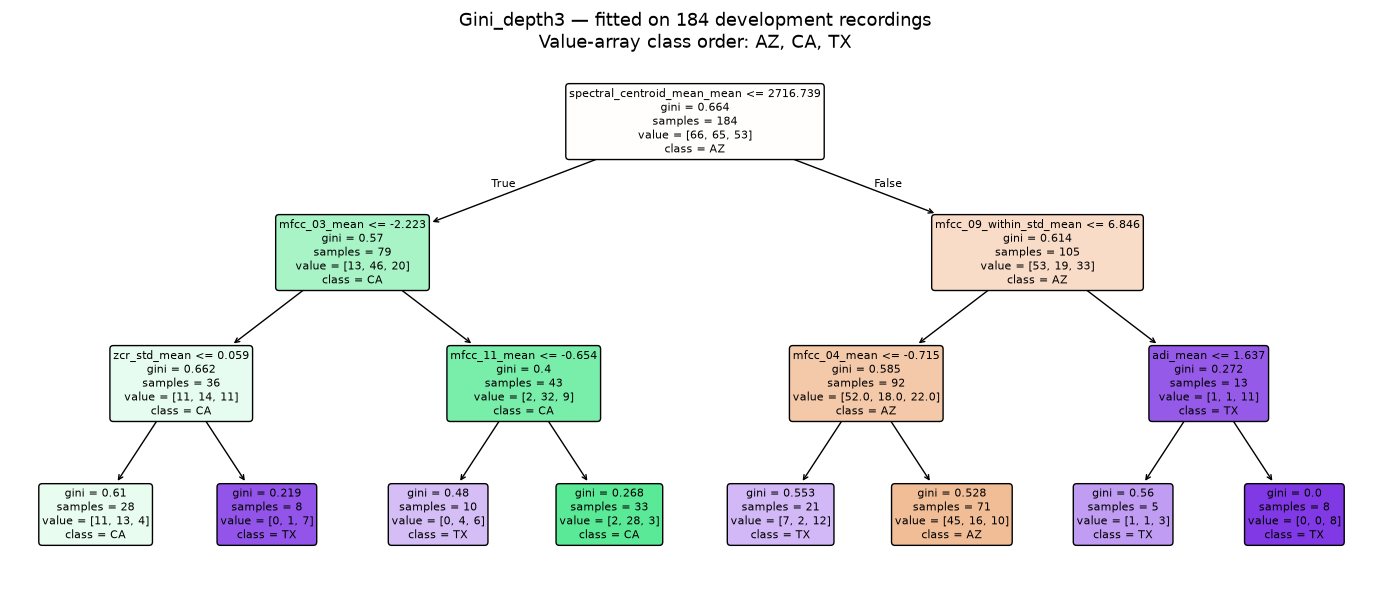

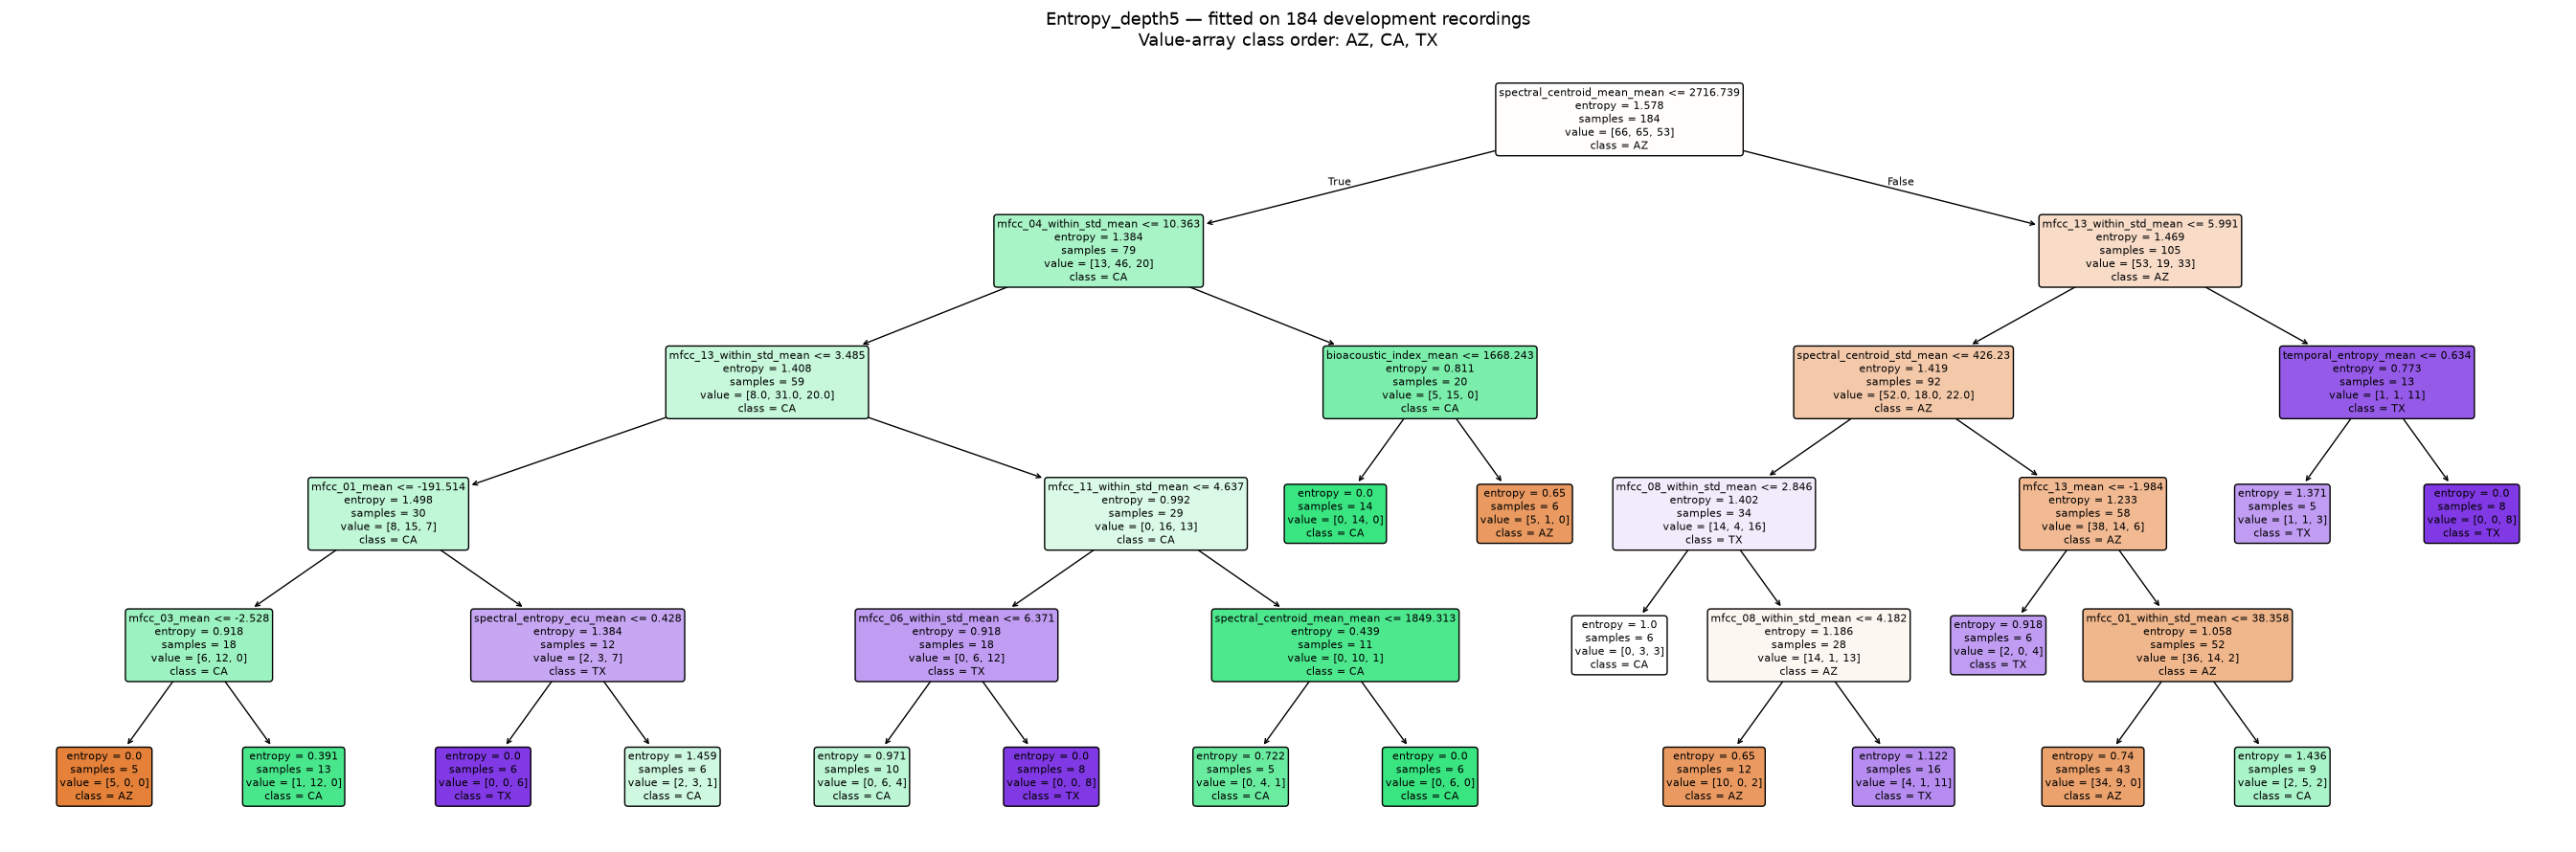

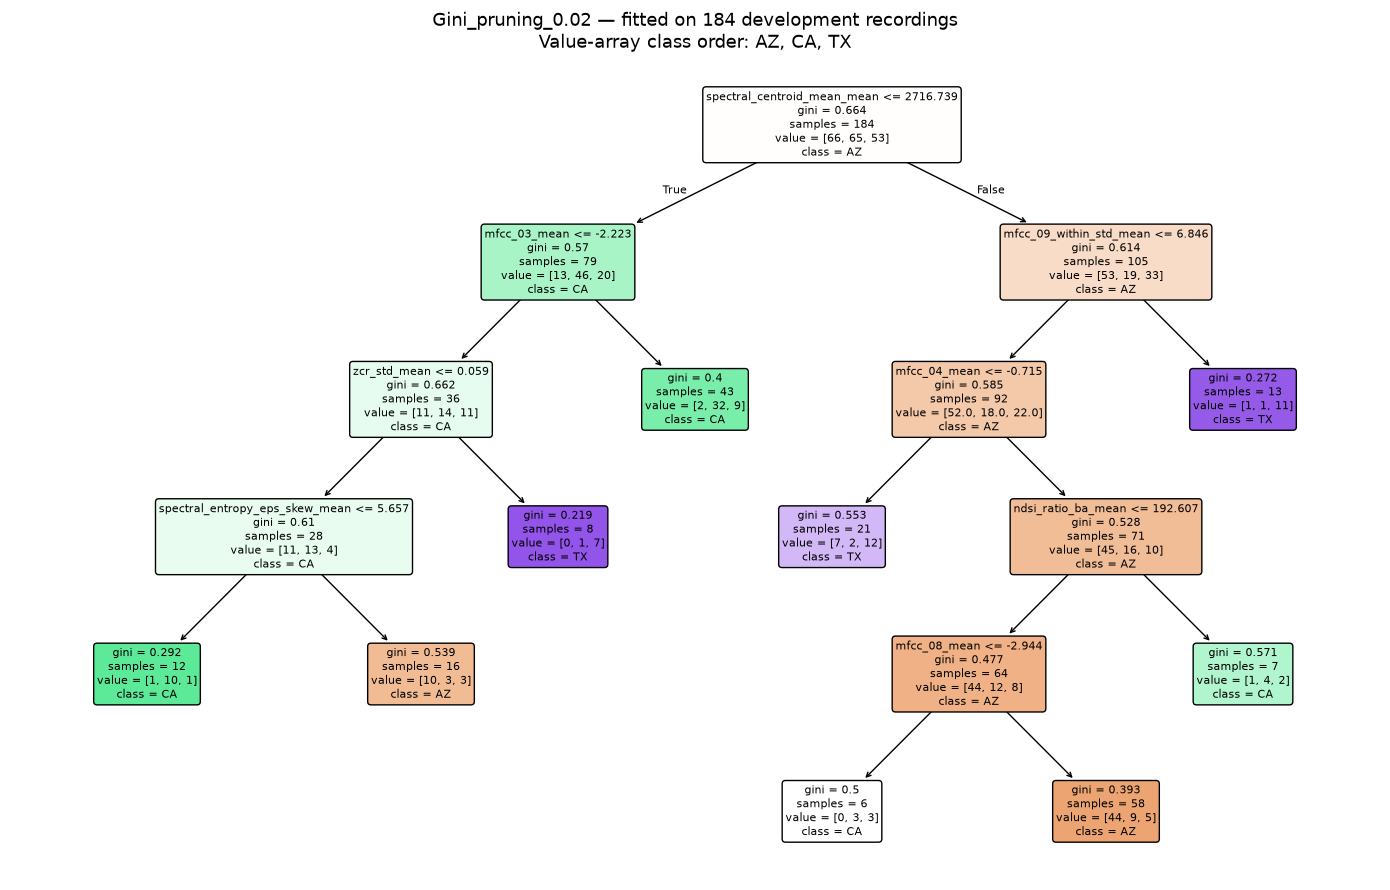

FULL-DEVELOPMENT TREE STRUCTURES
    configuration  training_recordings  depth  leaves  nodes                root_feature  root_threshold
      Gini_depth3                  184      3       8     15 spectral_centroid_mean_mean     2716.738525
   Entropy_depth5                  184      5      18     35 spectral_centroid_mean_mean     2716.738525
Gini_pruning_0.02                  184      5       9     17 spectral_centroid_mean_mean     2716.738525


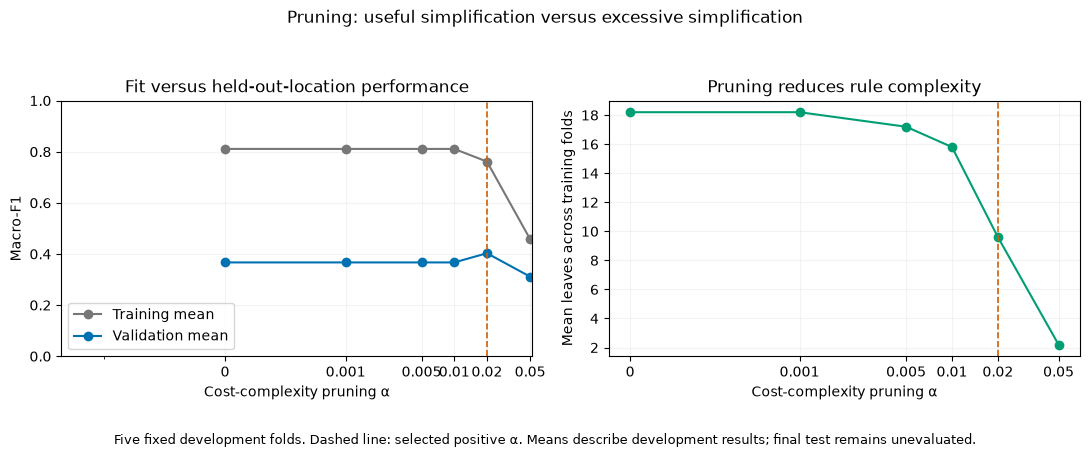


Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\decision_trees\development_search_20261030T031713485157Z\selected_tree_presentations_20261030T031939375802Z
Full trees saved as SVG, PNG, text rules, and fitted pipelines.
Final test remains unevaluated.


In [3]:

# Three actual fitted trees and pruning/complexity visualization.
# Development-only fits. No final-test access.

import joblib
from sklearn.tree import export_text

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
dt_presentation_dir = (
    dt_search_dir / f"selected_tree_presentations_{stamp}"
)
dt_presentation_dir.mkdir(parents=True, exist_ok=False)

fitted_tree_pipelines = {}
presentation_rows = []

for spec in selected_tree_specs:
    parameters = {
        key: spec[key]
        for key in [
            "criterion", "max_depth", "min_samples_leaf", "ccp_alpha"
        ]
    }

    pipeline = Pipeline([
        ("representation", make_representations()["continuous"]),
        ("classifier", DecisionTreeClassifier(
            **parameters, random_state=42
        )),
    ])
    pipeline.fit(X, y)

    classifier = pipeline.named_steps["classifier"]
    fitted_tree_pipelines[spec["name"]] = pipeline

    leaves = classifier.get_n_leaves()
    depth = classifier.get_depth()
    root_index = classifier.tree_.feature[0]
    root_feature = (
        feature_names[root_index] if root_index >= 0 else "NO_SPLIT"
    )

    presentation_rows.append({
        "configuration": spec["name"],
        "training_recordings": len(X),
        "depth": depth,
        "leaves": leaves,
        "nodes": classifier.tree_.node_count,
        "root_feature": root_feature,
        "root_threshold": (
            float(classifier.tree_.threshold[0])
            if root_index >= 0 else None
        ),
    })

    # Full tree: SVG supports readable zooming without truncation.
    fig, ax = plt.subplots(
        figsize=(
            max(14, leaves * 1.5),
            max(6, (depth + 1) * 1.5),
        )
    )
    plot_tree(
        classifier,
        feature_names=feature_names,
        class_names=list(classifier.classes_),
        filled=True,
        rounded=True,
        precision=3,
        fontsize=8,
        ax=ax,
    )
    ax.set_title(
        f"{spec['name']} — fitted on {len(X)} development recordings\n"
        f"Value-array class order: {', '.join(classifier.classes_)}",
        fontsize=13,
    )
    fig.tight_layout()

    # Preserve decimal points in names such as Gini_pruning_0.02.
    fig.savefig(
        dt_presentation_dir / f"{spec['name']}.svg",
        bbox_inches="tight",
    )
    fig.savefig(
        dt_presentation_dir / f"{spec['name']}.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    joblib.dump(
        pipeline,
        dt_presentation_dir / f"{spec['name']}.joblib",
    )
    (dt_presentation_dir / f"{spec['name']}_rules.txt").write_text(
        export_text(
            classifier,
            feature_names=feature_names,
            max_depth=100,
            decimals=6,
            show_weights=True,
        ),
        encoding="utf-8",
    )

tree_presentations = pd.DataFrame(presentation_rows)

print("FULL-DEVELOPMENT TREE STRUCTURES")
print(tree_presentations.to_string(index=False))

# Plot SAVED CV results, not performance of the full-development fits.
pruning = tree_summary.loc[
    tree_summary["family"].isin([
        "pruning_reference", "pruning_candidate"
    ])
].sort_values("alpha")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(
    pruning["alpha"],
    pruning["mean_train_macro_f1"],
    marker="o",
    label="Training mean",
    color="#777777",
)
axes[0].plot(
    pruning["alpha"],
    pruning["mean_macro_f1"],
    marker="o",
    label="Validation mean",
    color="#0072B2",
)
axes[0].set_ylabel("Macro-F1")
axes[0].set_ylim(0, 1)
axes[0].set_title("Fit versus held-out-location performance")
axes[0].legend()

axes[1].plot(
    pruning["alpha"],
    pruning["mean_leaves"],
    marker="o",
    color="#009E73",
)
axes[1].set_ylabel("Mean leaves across training folds")
axes[1].set_title("Pruning reduces rule complexity")

chosen_pruning_alpha = next(
    spec["ccp_alpha"]
    for spec in selected_tree_specs
    if spec["family"] == "pruning_candidate"
)

for ax in axes:
    ax.set_xscale("symlog", linthresh=0.001)
    ax.set_xticks(
        pruning["alpha"],
        labels=[f"{alpha:g}" for alpha in pruning["alpha"]],
    )
    ax.axvline(
        chosen_pruning_alpha,
        color="#D55E00",
        linestyle="--",
        linewidth=1.2,
    )
    ax.set_xlabel("Cost-complexity pruning α")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Pruning: useful simplification versus excessive simplification"
)
fig.text(
    0.5,
    0.015,
    "Five fixed development folds. Dashed line: selected positive α. "
    "Means describe development results; final test remains unevaluated.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.93])

fig.savefig(
    dt_presentation_dir / "pruning_tradeoff.png",
    dpi=180,
    bbox_inches="tight",
)
fig.savefig(
    dt_presentation_dir / "pruning_tradeoff.svg",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

tree_presentations.to_csv(
    dt_presentation_dir / "tree_structures.csv",
    index=False,
)
pruning.to_csv(
    dt_presentation_dir / "pruning_plot_data.csv",
    index=False,
)

print("\nSaved:", dt_presentation_dir)
print("Full trees saved as SVG, PNG, text rules, and fitted pipelines.")
print("Final test remains unevaluated.")

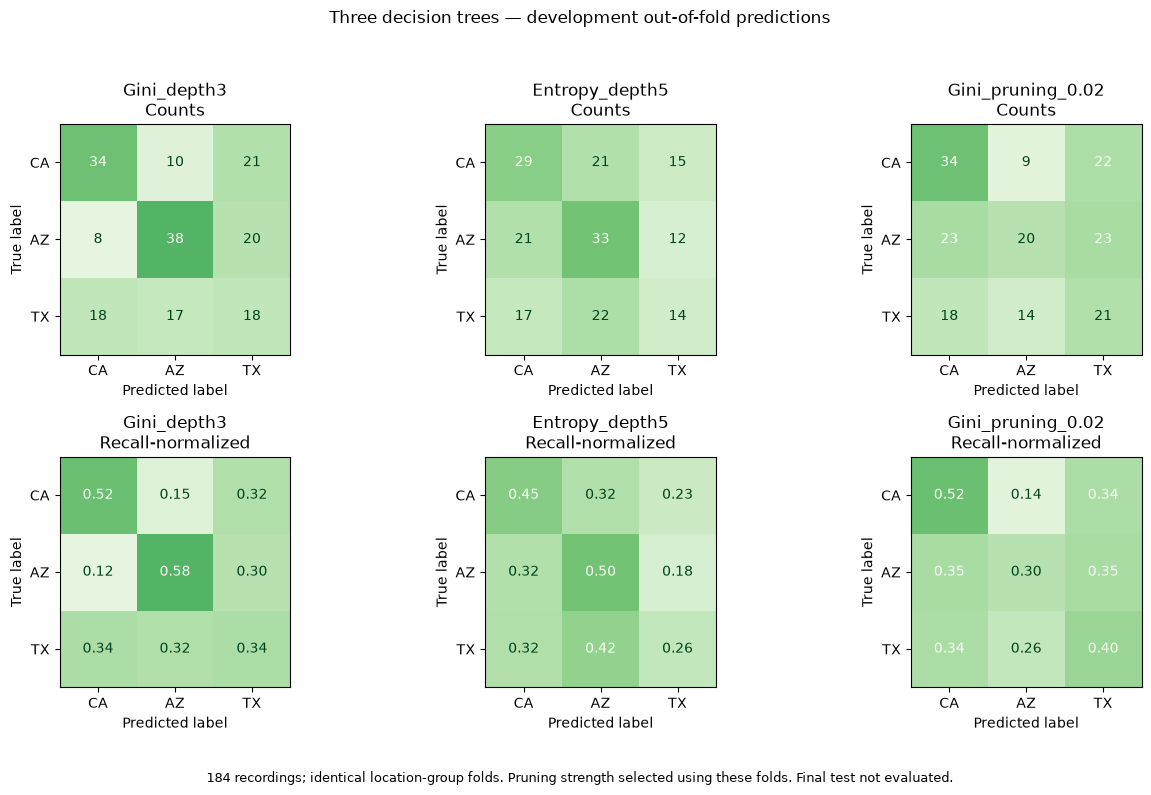

POOLED DEVELOPMENT SCORES
    configuration  pooled_oof_accuracy  pooled_oof_balanced_accuracy  pooled_oof_macro_f1
      Gini_depth3                0.489                         0.479                0.482
   Entropy_depth5                0.413                         0.403                0.401
Gini_pruning_0.02                0.408                         0.407                0.402

PER-STATE RECALL
state                 AZ     CA     TX
configuration                         
Entropy_depth5     0.500  0.446  0.264
Gini_depth3        0.576  0.523  0.340
Gini_pruning_0.02  0.303  0.523  0.396

ROOT FEATURE ACROSS FIVE TRAINING FOLDS
root_feature       rms_mean_mean  spectral_centroid_mean_mean  zcr_mean_mean
configuration                                                               
Entropy_depth5                 0                            3              2
Gini_depth3                    1                            3              1
Gini_pruning_0.02              1                    

In [4]:
#  Selected-tree OOF errors and root-feature consistency
# Reuses existing predictions. No refitting or final-test evaluation.

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

selected_names = [spec["name"] for spec in selected_tree_specs]
selected_tree_oof = tree_oof.loc[
    tree_oof["configuration"].isin(selected_names)
].copy()

assert selected_tree_oof.groupby("configuration").size().eq(184).all()
assert not selected_tree_oof.duplicated(
    ["configuration", "recording_id"]
).any()

summary_rows = []
class_rows = []

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for column, name in enumerate(selected_names):
    rows = selected_tree_oof.loc[
        selected_tree_oof["configuration"].eq(name)
    ]
    actual, predicted = rows["actual"], rows["predicted"]

    summary_rows.append({
        "configuration": name,
        "pooled_oof_accuracy": accuracy_score(actual, predicted),
        "pooled_oof_balanced_accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "pooled_oof_macro_f1": f1_score(
            actual, predicted, labels=CLASSES,
            average="macro", zero_division=0,
        ),
    })

    report = classification_report(
        actual, predicted, labels=CLASSES,
        output_dict=True, zero_division=0,
    )
    for state in CLASSES:
        class_rows.append({
            "configuration": name,
            "state": state,
            **report[state],
        })

    for row_index, normalization, value_format in [
        (0, None, "d"),
        (1, "true", ".2f"),
    ]:
        matrix = confusion_matrix(
            actual, predicted,
            labels=CLASSES, normalize=normalization,
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=CLASSES
        )
        display.plot(
            ax=axes[row_index, column],
            cmap="Greens",
            colorbar=False,
            values_format=value_format,
            im_kw={
                "vmin": 0,
                "vmax": 66 if normalization is None else 1,
            },
        )
        axes[row_index, column].set_title(
            f"{name}\n"
            + ("Counts" if normalization is None else "Recall-normalized")
        )

        suffix = "counts" if normalization is None else "normalized"
        pd.DataFrame(
            matrix,
            index=pd.Index(CLASSES, name="true_state"),
            columns=pd.Index(CLASSES, name="predicted_state"),
        ).to_csv(
            dt_presentation_dir / f"{name}_oof_confusion_{suffix}.csv"
        )

fig.suptitle("Three decision trees — development out-of-fold predictions")
fig.text(
    0.5, 0.015,
    "184 recordings; identical location-group folds. "
    "Pruning strength selected using these folds. Final test not evaluated.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
fig.savefig(
    dt_presentation_dir / "three_tree_oof_confusion_matrices.png",
    dpi=180, bbox_inches="tight",
)
fig.savefig(
    dt_presentation_dir / "three_tree_oof_confusion_matrices.svg",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

tree_oof_summary = pd.DataFrame(summary_rows)
tree_class_metrics = pd.DataFrame(class_rows)

print("POOLED DEVELOPMENT SCORES")
print(tree_oof_summary.round(3).to_string(index=False))

print("\nPER-STATE RECALL")
print(tree_class_metrics.pivot(
    index="configuration", columns="state", values="recall"
).round(3).to_string())

# Training-fold roots provide a limited stability diagnostic.
# Folds share training data; these are not independent experiments.
root_frequency = pd.crosstab(
    tree_fold_results.loc[
        tree_fold_results["configuration"].isin(selected_names),
        "configuration",
    ],
    tree_fold_results.loc[
        tree_fold_results["configuration"].isin(selected_names),
        "root_feature",
    ],
)

print("\nROOT FEATURE ACROSS FIVE TRAINING FOLDS")
print(root_frequency.to_string())

tree_oof_summary.to_csv(
    dt_presentation_dir / "selected_tree_oof_summary.csv", index=False
)
tree_class_metrics.to_csv(
    dt_presentation_dir / "selected_tree_class_metrics.csv", index=False
)
root_frequency.to_csv(
    dt_presentation_dir / "root_feature_frequency.csv"
)

print("\nSaved:", dt_presentation_dir)
print("No models refitted. Final test remains unevaluated.")

In [5]:
# Explain one held-out prediction and checkpoint tree selection
# Reproduces a development-fold prediction; no final-test evaluation.

# Highest mean-fold macro-F1 among the tested tree configurations.
winner = tree_summary.sort_values(
    ["mean_macro_f1", "mean_leaves"],
    ascending=[False, True],
).iloc[0]["configuration"]

assert winner == "Gini_depth3"

selected_dt_spec = next(
    spec for spec in tree_specs if spec["name"] == winner
)

validation_mask = fold_manifest["validation_fold"].eq(0)
tr = np.flatnonzero(~validation_mask.to_numpy())
va = np.flatnonzero(validation_mask.to_numpy())
position = va[0]  # Fixed selection, not chosen for a correct prediction.

example_id = fold_manifest.iloc[position]["recording_id"]

parameters = {
    key: selected_dt_spec[key]
    for key in ["criterion", "max_depth", "min_samples_leaf", "ccp_alpha"]
}
explanation_pipeline = Pipeline([
    ("representation", make_representations()["continuous"]),
    ("classifier", DecisionTreeClassifier(
        **parameters, random_state=42
    )),
])
explanation_pipeline.fit(X.iloc[tr], y.iloc[tr])

representation = explanation_pipeline.named_steps["representation"]
classifier = explanation_pipeline.named_steps["classifier"]
example_values = representation.transform(X.iloc[[position]])
prediction = explanation_pipeline.predict(X.iloc[[position]])[0]

stored = tree_oof.loc[
    tree_oof["configuration"].eq(winner)
    & tree_oof["recording_id"].eq(example_id),
    "predicted",
]
assert len(stored) == 1
assert prediction == stored.iloc[0]

# Traverse using the same float32 precision as sklearn.
tree = classifier.tree_
values32 = example_values.astype(np.float32)[0]
path_rows = []
node = 0

while tree.children_left[node] != tree.children_right[node]:
    feature_index = tree.feature[node]
    threshold = tree.threshold[node]
    value = float(values32[feature_index])
    goes_left = value <= threshold

    path_rows.append({
        "step": len(path_rows) + 1,
        "node": node,
        "feature": feature_names[feature_index],
        "recording_value": value,
        "threshold": float(threshold),
        "comparison": "<=" if goes_left else ">",
        "branch": "left" if goes_left else "right",
        "training_recordings_at_node": int(tree.n_node_samples[node]),
    })
    node = (
        tree.children_left[node] if goes_left
        else tree.children_right[node]
    )

assert node == classifier.apply(example_values)[0]
decision_path_table = pd.DataFrame(path_rows)

# Count actual training labels reaching this leaf; no assumptions about
# whether sklearn's tree_.value stores proportions or counts.
training_values = representation.transform(X.iloc[tr])
training_leaves = classifier.apply(training_values)
leaf_labels = y.iloc[tr].to_numpy()[training_leaves == node]

leaf_composition = pd.DataFrame({
    "state": CLASSES,
    "training_recordings": [
        int((leaf_labels == state).sum()) for state in CLASSES
    ],
})
leaf_composition["fraction"] = (
    leaf_composition["training_recordings"] / len(leaf_labels)
)
assert len(leaf_labels) == tree.n_node_samples[node]

print("HELD-OUT DEVELOPMENT EXAMPLE")
print("Recording:", example_id)
print("Actual state:", y.iloc[position])
print("Predicted state:", prediction)

print("\nDECISION PATH")
print(decision_path_table.round(5).to_string(index=False))

print("\nTRAINING RECORDINGS IN THE REACHED LEAF")
print(leaf_composition.round(3).to_string(index=False))
print("Leaf fractions are training composition, not calibrated confidence.")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
dt_checkpoint_dir = dt_search_dir / f"selected_checkpoint_{stamp}"
dt_checkpoint_dir.mkdir(parents=True, exist_ok=False)

decision_path_table.to_csv(
    dt_checkpoint_dir / "worked_prediction_path.csv", index=False
)
leaf_composition.to_csv(
    dt_checkpoint_dir / "worked_prediction_leaf.csv", index=False
)

(dt_checkpoint_dir / "selected_tree.json").write_text(
    json.dumps({
        "configuration": selected_dt_spec,
        "selection_metric": "Mean development-fold macro-F1",
        "selection_score": float(
            tree_summary.loc[
                tree_summary["configuration"].eq(winner), "mean_macro_f1"
            ].iloc[0]
        ),
        "feature_allowlist": feature_names,
        "fold_manifest": artifacts["development_folds"],
        "worked_example": {
            "recording_id": str(example_id),
            "validation_fold": 0,
            "actual": str(y.iloc[position]),
            "predicted": str(prediction),
            "leaf_training_n": len(leaf_labels),
        },
        "final_test_evaluated": False,
        "limitations": [
            "Configuration selected using the reported development folds.",
            "Root features vary across training folds.",
            "Regional labels remain confounded with sampling and species.",
            "Leaf proportions are not calibrated probabilities.",
        ],
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved tree checkpoint:", dt_checkpoint_dir)
print("Final test remains unevaluated.")

HELD-OUT DEVELOPMENT EXAMPLE
Recording: 1080405
Actual state: AZ
Predicted state: TX

DECISION PATH
 step  node                     feature  recording_value   threshold comparison branch  training_recordings_at_node
    1     0 spectral_centroid_mean_mean       3638.76807  2335.96021          >  right                          150
    2     6               biophony_mean     126278.06250 74114.58984          >  right                          100
    3    10                mfcc_03_mean        -23.90857   -10.80053         <=   left                           44

TRAINING RECORDINGS IN THE REACHED LEAF
state  training_recordings  fraction
   CA                    1     0.059
   AZ                    2     0.118
   TX                   14     0.824
Leaf fractions are training composition, not calibrated confidence.

Saved tree checkpoint: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\decision_trees\development_search_20261030T031713485157Z\selecte